# 01 · Ghost Games: Headline Results

**Question:** When COVID emptied stadiums, how much of football's home advantage disappeared?

Steps: load results → add real attendance → label each match (fans / partial / empty) → raw comparison → model with team strength → home advantage over time.

In [1]:
import matplotlib.pyplot as plt

from ghost_games.attendance import (
    add_crowd_share,
    apply_overrides,
    load_attendance,
    match_team_names,
    merge_attendance,
)
from ghost_games.data import load_matches
from ghost_games.inference import bootstrap_gap, permutation_test
from ghost_games.model import fit_home_advantage, home_advantage_over_time
from ghost_games.outcomes import add_outcomes
from ghost_games.treatment import (
    assign_crowd_status_from_attendance,
    compare_with_dates,
    load_windows,
)

results = load_matches("../data/raw")
attendance = load_attendance("../data/raw/attendance")
len(results), len(attendance)

(14507, 14635)

## 1. Match team names between the two sources
Check every row with `date_overlap` below 0.9. Put any fixes in `config/team_names.csv`.

In [2]:
mapping = apply_overrides(match_team_names(results, attendance), "../config/team_names.csv")
mapping[mapping["date_overlap"].fillna(1) < 0.9]

,league,fbref_name,results_name,date_overlap,similarity


In [3]:
matches = add_crowd_share(merge_attendance(results, attendance, mapping))
print(f"Attendance found for {matches.attrs['attendance_coverage']:.1%} of matches")
windows = load_windows("../config/closed_doors.csv")
matches = add_outcomes(assign_crowd_status_from_attendance(matches, windows))
matches.groupby(["season", "crowd_status"]).size().unstack(fill_value=0)

Attendance found for 85.1% of matches


crowd_status,empty,fans,partial,unknown
season,,,,
2015-16,0,1792,34,0
2016-17,0,1767,54,5
2017-18,0,1808,16,2
2018-19,0,1810,14,2
2019-20,408,1296,12,9
2020-21,1597,0,229,0
2021-22,17,1395,398,16
2022-23,0,1816,9,1


## 2. Do the config dates agree with real attendance?
Numbers off the diagonal mean a date window is wrong.

In [4]:
compare_with_dates(matches)

from attendance,fans,partial,All
from dates,,,
empty,8,90,98
fans,11676,463,12139
partial,0,104,104
All,11684,657,12341


## 3. Raw comparison (no controls)

In [5]:
main = matches[matches.crowd_status != "partial"]
for outcome in ["goal_diff", "points_diff", "card_gap"]:
    fans = main.loc[main.closed_doors == 0, outcome]
    empty = main.loc[main.closed_doors == 1, outcome]
    gap = bootstrap_gap(fans, empty)
    p = permutation_test(fans, empty, n_permutations=2000)
    print(
        f"{outcome:12s} fans={gap.fans_mean:+.3f} empty={gap.empty_mean:+.3f} "
        f"diff={gap.difference:+.3f} [{gap.ci_low:+.3f}, {gap.ci_high:+.3f}] p={p:.4f}"
    )

goal_diff    fans=+0.338 empty=+0.135 diff=-0.203 [-0.288, -0.119] p=0.0005
points_diff  fans=+0.449 empty=+0.142 diff=-0.307 [-0.428, -0.192] p=0.0005
card_gap     fans=+0.261 empty=-0.011 diff=-0.272 [-0.351, -0.191] p=0.0005


## 4. Controlling for team strength
First fans vs empty, then crowd size as a continuous variable (uses the partial-crowd games too).

In [6]:
for treatment in ["closed_doors", "crowd_share"]:
    print(f"--- {treatment}")
    for outcome in ["goal_diff", "points_diff", "card_gap"]:
        fit = fit_home_advantage(matches, outcome, treatment=treatment)
        print(
            f"{outcome:12s} home_adv={fit.home_adv:+.3f} effect={fit.effect:+.3f} "
            f"CI={fit.ci[0]:+.3f}..{fit.ci[1]:+.3f} n={fit.n_matches} "
            f"share of edge from crowd={fit.share_of_advantage_lost:.0%}"
        )

--- closed_doors
goal_diff    home_adv=+0.347 effect=-0.209 CI=-0.285..-0.134 n=13706 share of edge from crowd=60%
points_diff  home_adv=+0.460 effect=-0.310 CI=-0.419..-0.200 n=13706 share of edge from crowd=67%
card_gap     home_adv=+0.264 effect=-0.277 CI=-0.355..-0.200 n=13706 share of edge from crowd=105%
--- crowd_share


/Users/kaanakar/Projects/portfolio/ghost-games/src/ghost_games/model.py:103: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  result = sm.OLS(data[outcome].astype(float), design).fit(cov_type="HC1")


goal_diff    home_adv=+0.376 effect=-0.029 CI=-0.167..+0.109 n=12341 share of edge from crowd=-8%


/Users/kaanakar/Projects/portfolio/ghost-games/src/ghost_games/model.py:103: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  result = sm.OLS(data[outcome].astype(float), design).fit(cov_type="HC1")


points_diff  home_adv=+0.508 effect=-0.050 CI=-0.243..+0.142 n=12341 share of edge from crowd=-11%
card_gap     home_adv=+0.334 effect=-0.070 CI=-0.210..+0.070 n=12341 share of edge from crowd=-27%


/Users/kaanakar/Projects/portfolio/ghost-games/src/ghost_games/model.py:103: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  result = sm.OLS(data[outcome].astype(float), design).fit(cov_type="HC1")


## 5. Home advantage over time

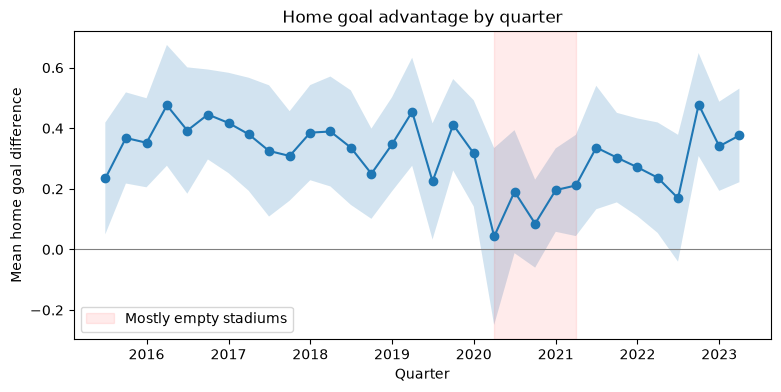

In [7]:
summary = home_advantage_over_time(matches, "goal_diff", freq="QS")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(summary["date"], summary["mean"], marker="o")
ax.fill_between(summary["date"], summary["ci_low"], summary["ci_high"], alpha=0.2)
ax.axhline(0, color="grey", linewidth=0.8)
empty_quarters = summary[summary["share_empty"] > 0.5]["date"]
if not empty_quarters.empty:
    ax.axvspan(
        empty_quarters.min(),
        empty_quarters.max(),
        color="red",
        alpha=0.08,
        label="Mostly empty stadiums",
    )
ax.set_title("Home goal advantage by quarter")
ax.set_xlabel("Quarter")
ax.set_ylabel("Mean home goal difference")
ax.legend()
plt.show()
# Takeaway: TODO